In [23]:
import os
import numpy as np
from pathlib import Path
from PIL import Image
from tensorflow.keras import models,layers
import matplotlib.pyplot as plt
import cv2

In [ ]:
data_dir_train = Path("")
data_dir_test = Path("")

In [15]:
healthy_train = list(data_dir_train.glob("healthy/*.*"))
unhealthy_train = list(data_dir_train.glob("unhealthy/*.*"))
healthy_test = list(data_dir_test.glob("healthy/*.*"))
unhealthy_test = list(data_dir_test.glob("unhealthy/*.*"))

In [16]:
len(healthy_train),len(unhealthy_train),len(healthy_test),len(unhealthy_test)

(383, 1000, 62, 452)

In [51]:
def normalize(images):
    image_list = []
    
    for i in range(len(images)):
        img = cv2.imread(images[i])
        img = cv2.resize(img, (224, 224))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        image_list.append(img.astype("float32"))
    
    return np.array(image_list)

In [52]:
healthy_train_np = normalize(healthy_train.copy())
unhealthy_train_np = normalize(unhealthy_train.copy())
healthy_test_np = normalize(healthy_test.copy())
unhealthy_test_np = normalize(unhealthy_test.copy())

In [53]:
healthy_train_np.shape,unhealthy_train_np.shape,healthy_test_np.shape,unhealthy_test_np.shape

((383, 224, 224, 3),
 (1000, 224, 224, 3),
 (62, 224, 224, 3),
 (452, 224, 224, 3))

In [127]:
augmenter = models.Sequential(
    [
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.10),
        layers.RandomZoom((-0.15, 0.15)),
        layers.RandomTranslation(0.05, 0.05),
        layers.RandomBrightness(0.15),
        layers.RandomContrast(0.15),
    ],    
)

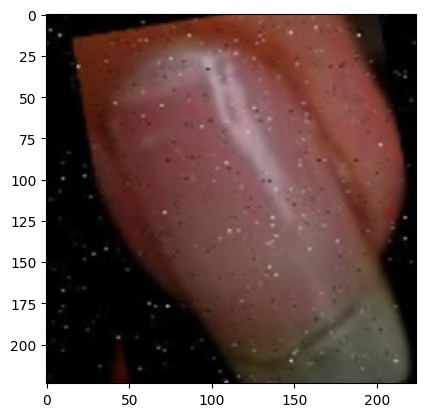

In [126]:
plt.imshow(healthy_train_np[37]/255);

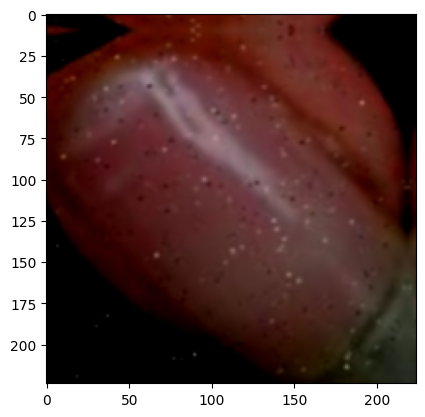

In [125]:
plt.imshow(augmenter(healthy_train_np[37])/255);

In [60]:
def augment_data(minority, target):
    aug_list = []
    count = len(minority)
    while count < target:
        r_index = np.random.randint(0, len(minority))
        random_img = minority[r_index]
        augmented_img = augmenter(random_img, training=True)

        aug_list.append(augmented_img)
        count += 1

    aug_list = np.array(aug_list)

    result = np.concatenate([minority, aug_list])
    return result

In [134]:
healthy_train_augmented = augment_data(healthy_train_np,1000)
healthy_train_augmented.shape

(1000, 224, 224, 3)

In [135]:
X_train_combined = np.concatenate([healthy_train_augmented,unhealthy_train_np])
X_train_combined.shape

(2000, 224, 224, 3)

In [141]:
X_test_combined = np.concatenate([healthy_test_np,unhealthy_test_np])
X_test_combined.shape

(514, 224, 224, 3)

In [140]:
y_train_healthy = np.full(healthy_train_augmented.shape[0],0)
y_train_unhealthy = np.full(unhealthy_train_np.shape[0],1)
y_train_combined = np.concatenate([y_train_healthy,y_train_unhealthy])
y_train_combined.shape

(2000,)

In [142]:
y_test_healthy = np.full(healthy_test_np.shape[0],0)
y_test_unhealthy = np.full(unhealthy_test_np.shape[0],1)
y_test_combined = np.concatenate([y_test_healthy,y_test_unhealthy])
y_test_combined.shape

(514,)

In [144]:
np.savez_compressed("nails_training_dataset_binary_classification",X_train = X_train_combined,y_train = y_train_combined)

In [ ]:
np.savez_compressed("nails_testing_dataset_binary_classification",X_test = X_test_combined,y_test = y_test_combined)